# Automated Remote Fixing & Self-Healing Prototype

**Project:** Omni-Grid Renewable Energy Intelligence Platform  
**Model:** Automated Remote Fixing & Self-Healing  
**Prototype Version:** v1.0  
**Objective:** Diagnose inverter fault conditions, recommend safe remote remediation actions, apply safety-gating rules, and generate an auditable action plan.

---

## Prototype Scope

This notebook implements the first prototype for the **Automated Remote Fixing & Self-Healing** model using the provided synthetic inverter telemetry dataset.

The prototype includes:

1. Data loading and validation
2. Exploratory data analysis
3. Fault-signature generation from telemetry patterns
4. Fault diagnosis model
5. Failure-risk model
6. Rule-based remediation policy
7. Safety gate for autonomous action eligibility
8. Rollback simulation logic
9. Audit trail generation
10. Exported prediction and model artefacts

---

## Important Design Note

The PRD describes a future Reinforcement Learning remediation agent. However, the current dataset contains inverter telemetry and failure labels, but it does **not** contain historical remediation actions and post-action success/failure outcomes.

Because of that, this first prototype uses a safer and more realistic approach:

- **Machine learning** for fault diagnosis and short-term failure-risk estimation
- **Rule-based expert system** for remediation recommendations
- **Safety gate** to prevent unsafe autonomous actions
- **Rollback simulation** to represent how production rollback logic would behave

A true RL agent can be added later when there is a digital twin or historical action-outcome data.

## 1. Environment Setup

This section imports the required libraries and configures the project directory. The notebook is written so it can run from your local project folder, or from any folder where the CSV files are stored next to the notebook.

In [1]:
# Core libraries
import os
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Machine learning
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    RocCurveDisplay,
)

# Exporting models
import joblib

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
# ================================================================
# Data paths (portable)
# ================================================================
# Run this notebook from its own module folder. Data lives in ./data.
# If the full synthetic dataset is not present, the sample file is used
# so the notebook still runs end to end for anyone who clones the repo.

DATA_DIR = Path.cwd() / "data"
DATASET_PATH = DATA_DIR / "synthetic_rfsh_dataset.csv"
SAMPLE_PATH = DATA_DIR / "synthetic_rfsh_sample.csv"
DICTIONARY_PATH = DATA_DIR / "synthetic_rfsh_data_dictionary.csv"

if not DATASET_PATH.exists():
    print(f"Full dataset not found, using sample file: {SAMPLE_PATH.name}")
    DATASET_PATH = SAMPLE_PATH

base_dir = Path.cwd()
output_dir = base_dir / "outputs"
model_dir = base_dir / "models"
output_dir.mkdir(exist_ok=True)
model_dir.mkdir(exist_ok=True)
print("Dataset path:", DATASET_PATH)


## 2. Load Dataset and Data Dictionary

The dataset contains inverter-level operational telemetry such as temperature, efficiency, insulation resistance, restart counts, error counts, and future failure labels. The dictionary file is used to understand the meaning of each column.

In [ ]:
df = pd.read_csv(DATASET_PATH)
data_dictionary = pd.read_csv(DICTIONARY_PATH)

print("Dataset shape:", df.shape)
print("Dictionary shape:", data_dictionary.shape)

display(df.head())
display(data_dictionary.head(10))

In [4]:
# Basic schema inspection
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nMissing values:")
missing_summary = df.isna().sum().sort_values(ascending=False).to_frame("missing_count")
missing_summary["missing_percent"] = (missing_summary["missing_count"] / len(df) * 100).round(2)
display(missing_summary.head(20))

Column names:
['date', 'inverter_id', 'manufacturer', 'climate_zone', 'rated_capacity_kw', 'installation_quality_score', 'maintenance_quality_score', 'age_months', 'ambient_temperature_c', 'humidity_pct', 'dust_soiling_index', 'uv_exposure_index', 'cumulative_uv_exposure', 'operating_hours_today', 'cumulative_operating_hours', 'cumulative_energy_throughput_mwh', 'efficiency_pct', 'reactive_power_capability', 'internal_temperature_c', 'voltage_ripple', 'current_harmonic_distortion_pct', 'insulation_resistance_mohm', 'capacitor_degradation_indicator', 'fan_speed_rpm', 'restart_count_today', 'error_code_count_today', 'thermal_cycling_count_today', 'overload_events_today', 'failure_within_7d', 'failure_within_30d', 'failure_within_90d', 'rul_days', 'failed_today', 'is_censored', 'efficiency_7d_mean', 'efficiency_30d_mean', 'temperature_7d_mean', 'temperature_30d_mean', 'efficiency_decline_7d', 'temp_stress_index', 'restart_7d_sum', 'errors_7d_sum']

Data types:


,dtype
date,object
inverter_id,object
manufacturer,object
climate_zone,object
rated_capacity_kw,int64
installation_quality_score,float64
maintenance_quality_score,float64
age_months,float64
ambient_temperature_c,float64
humidity_pct,float64



Missing values:


,missing_count,missing_percent
rul_days,17155,52.58
date,0,0.00
fan_speed_rpm,0,0.00
restart_count_today,0,0.00
error_code_count_today,0,0.00
thermal_cycling_count_today,0,0.00
overload_events_today,0,0.00
failure_within_7d,0,0.00
failure_within_30d,0,0.00
failure_within_90d,0,0.00


## 3. Data Preparation

This section prepares the data for modelling:

- Convert `date` into a datetime field
- Sort each inverter chronologically
- Create useful time-based features
- Check target label distributions

In [5]:
# Convert date column and sort by inverter/time

df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.sort_values(["inverter_id", "date"]).reset_index(drop=True)

# Time-based features
# These are useful because inverter behaviour can vary by month and season.
df["month"] = df["date"].dt.month
df["quarter"] = df["date"].dt.quarter
df["day_of_year"] = df["date"].dt.dayofyear

def season_from_month(month):
    if month in [12, 1, 2]:
        return "summer"
    if month in [3, 4, 5]:
        return "autumn"
    if month in [6, 7, 8]:
        return "winter"
    return "spring"

df["season"] = df["month"].apply(season_from_month)

print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of inverters:", df["inverter_id"].nunique())
print("Rows after preparation:", df.shape[0])

display(df.head())

Date range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Number of inverters: 120
Rows after preparation: 32627


,date,inverter_id,manufacturer,climate_zone,rated_capacity_kw,installation_quality_score,maintenance_quality_score,age_months,ambient_temperature_c,humidity_pct,dust_soiling_index,uv_exposure_index,cumulative_uv_exposure,operating_hours_today,cumulative_operating_hours,cumulative_energy_throughput_mwh,efficiency_pct,reactive_power_capability,internal_temperature_c,voltage_ripple,current_harmonic_distortion_pct,insulation_resistance_mohm,capacitor_degradation_indicator,fan_speed_rpm,restart_count_today,error_code_count_today,thermal_cycling_count_today,overload_events_today,failure_within_7d,failure_within_30d,failure_within_90d,rul_days,failed_today,is_censored,efficiency_7d_mean,efficiency_30d_mean,temperature_7d_mean,temperature_30d_mean,efficiency_decline_7d,temp_stress_index,restart_7d_sum,errors_7d_sum,month,quarter,day_of_year,season
0,2025-01-01,INV-0001,Fronius,Temperate,100,0.789,0.88,83.00,19.57,40.05,0.292,6.43,6.43,11.78,11.78,1.161,97.93,1.057,28.51,2.631,5.431,79.04,0.427,2676.3,0,0,3,0,0,0,0,127.0,0,0,97.9300,97.9300,28.510000,28.510000,0.0000,0.0,0.0,0.0,1,1,1,summer
1,2025-01-02,INV-0001,Fronius,Temperate,100,0.789,0.88,83.03,23.48,41.48,0.346,6.33,12.76,12.30,24.08,2.112,97.46,1.076,36.64,2.569,5.509,77.96,0.383,2573.1,0,0,0,0,0,0,0,126.0,0,0,97.6950,97.6950,32.575000,32.575000,-0.2350,0.0,0.0,0.0,1,1,2,summer
2,2025-01-03,INV-0001,Fronius,Temperate,100,0.789,0.88,83.07,21.69,45.80,0.329,7.88,20.64,12.34,36.42,2.967,98.04,0.958,32.22,3.072,5.553,80.58,0.295,2865.0,0,0,0,0,0,0,0,125.0,0,0,97.8100,97.8100,32.456667,32.456667,0.2300,0.0,0.0,0.0,1,1,3,summer
3,2025-01-04,INV-0001,Fronius,Temperate,100,0.789,0.88,83.10,21.43,22.49,0.186,7.09,27.74,10.41,46.83,3.794,97.48,1.039,35.10,2.268,5.643,76.89,0.502,2451.1,0,0,4,1,0,0,0,124.0,0,0,97.7275,97.7275,33.117500,33.117500,-0.2475,0.0,0.0,0.0,1,1,4,summer
4,2025-01-05,INV-0001,Fronius,Temperate,100,0.789,0.88,83.13,23.25,33.41,0.368,6.04,33.78,14.66,61.49,5.075,98.43,0.926,36.49,2.869,5.472,82.03,0.367,2605.3,0,0,0,0,0,0,0,123.0,0,0,97.8680,97.8680,33.792000,33.792000,0.5620,0.0,0.0,0.0,1,1,5,summer


In [6]:
# Target distributions
failure_cols = ["failure_within_7d", "failure_within_30d", "failure_within_90d", "failed_today", "is_censored"]

for col in failure_cols:
    if col in df.columns:
        print(f"\n{col} distribution:")
        display(df[col].value_counts(dropna=False).to_frame("count"))
        display((df[col].value_counts(normalize=True, dropna=False) * 100).round(2).to_frame("percent"))


failure_within_7d distribution:


,count
failure_within_7d,
0,32044
1,583


,percent
failure_within_7d,
0,98.21
1,1.79



failure_within_30d distribution:


,count
failure_within_30d,
0,30365
1,2262


,percent
failure_within_30d,
0,93.07
1,6.93


... (5 outputs left out)

,percent
failed_today,
0,99.78
1,0.22



is_censored distribution:


,count
is_censored,
1,17155
0,15472


,percent
is_censored,
1,52.58
0,47.42


## 4. Exploratory Data Analysis

This section checks how key telemetry variables behave across normal and risky inverter states. The aim is to understand which signals may indicate remote-fix opportunities or escalation risk.

In [7]:
# Numeric summary
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
summary = df[numeric_cols].describe().T
summary["missing"] = df[numeric_cols].isna().sum()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,missing
rated_capacity_kw,32627.0,118.524,69.349,50.000,75.000,100.000,150.000,250.000,0
installation_quality_score,32627.0,0.878,0.071,0.760,0.816,0.879,0.941,1.000,0
maintenance_quality_score,32627.0,0.855,0.084,0.706,0.779,0.859,0.929,0.999,0
age_months,32627.0,72.086,30.464,12.000,46.800,71.900,95.930,131.130,0
ambient_temperature_c,32627.0,25.011,5.298,1.670,21.450,25.000,28.580,45.050,0
humidity_pct,32627.0,56.806,17.286,10.000,43.770,56.590,69.770,100.000,0
dust_soiling_index,32627.0,0.428,0.179,0.000,0.299,0.402,0.544,1.000,0
uv_exposure_index,32627.0,6.191,1.393,1.000,5.250,6.190,7.130,10.000,0
cumulative_uv_exposure,32627.0,960.580,622.356,3.230,424.790,888.310,1441.830,2342.420,0
operating_hours_today,32627.0,11.507,1.205,6.490,10.700,11.510,12.330,15.000,0


In [8]:
# Failure rate by manufacturer, climate zone, and season
for group_col in ["manufacturer", "climate_zone", "season"]:
    if group_col in df.columns:
        grouped = (
            df.groupby(group_col)["failure_within_7d"]
            .agg(["count", "mean"])
            .rename(columns={"mean": "failure_within_7d_rate"})
            .sort_values("failure_within_7d_rate", ascending=False)
        )
        grouped["failure_within_7d_rate"] = (grouped["failure_within_7d_rate"] * 100).round(2)
        print(f"\nFailure within 7 days by {group_col}:")
        display(grouped)


Failure within 7 days by manufacturer:


,count,failure_within_7d_rate
manufacturer,,
Huawei,5254,2.28
SMA,13334,1.98
Fronius,8858,1.52
SolarEdge,5181,1.24



Failure within 7 days by climate_zone:


,count,failure_within_7d_rate
climate_zone,,
Humid-Subtropical,5301,2.26
Hot-Dry,8572,1.87
Temperate,8632,1.75
Coastal,10122,1.50



Failure within 7 days by season:


,count,failure_within_7d_rate
season,,
spring,5760,3.04
winter,8179,2.23
autumn,10034,1.58
summer,8654,0.77


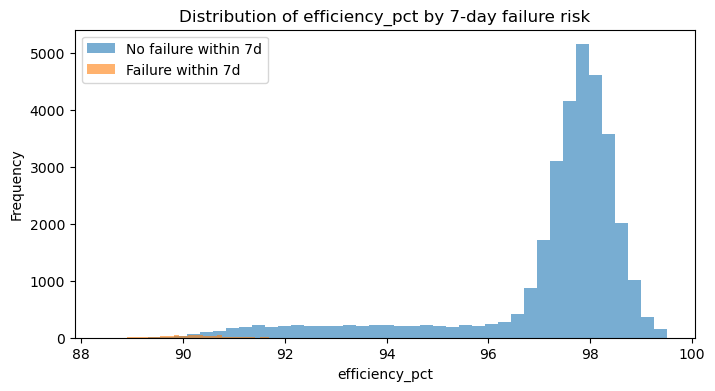

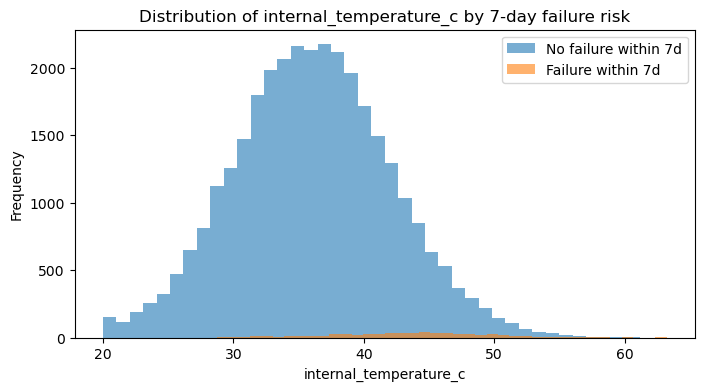

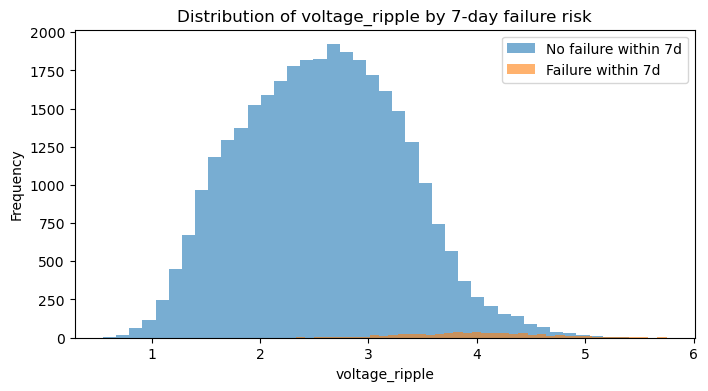

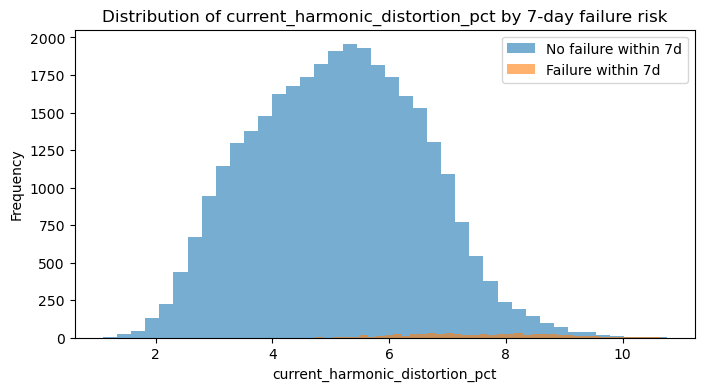

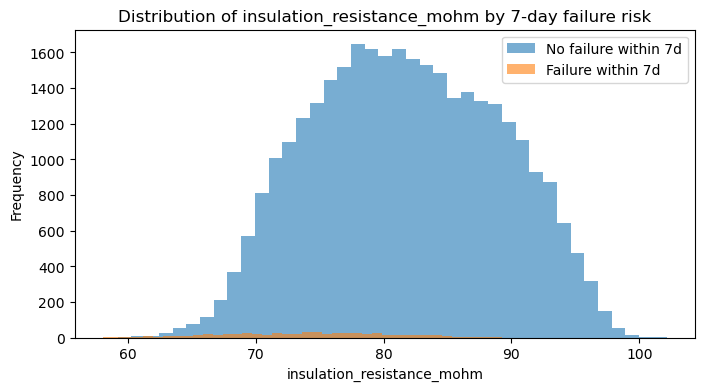

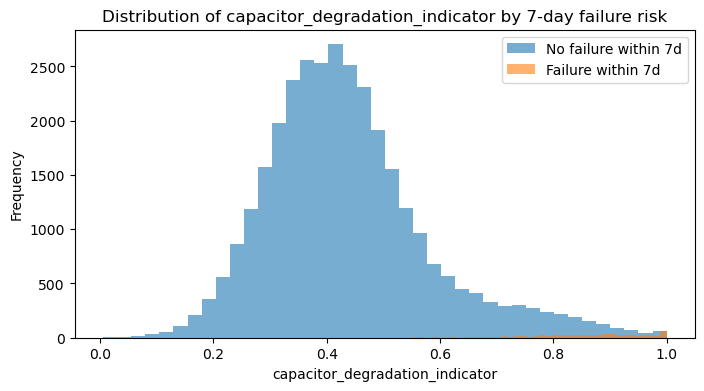

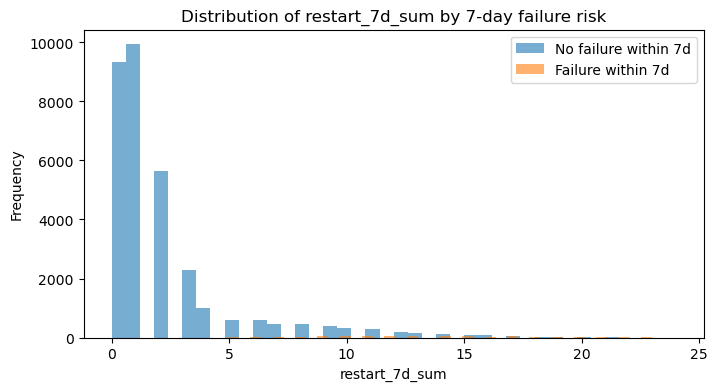

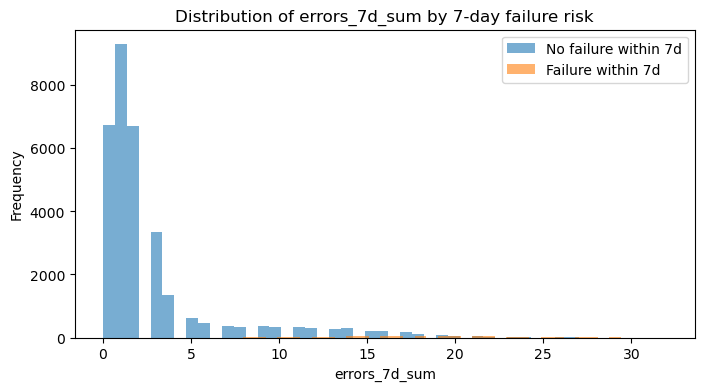

In [9]:
# Plot key telemetry distributions split by failure risk
plot_cols = [
    "efficiency_pct",
    "internal_temperature_c",
    "voltage_ripple",
    "current_harmonic_distortion_pct",
    "insulation_resistance_mohm",
    "capacitor_degradation_indicator",
    "restart_7d_sum",
    "errors_7d_sum",
]

available_plot_cols = [c for c in plot_cols if c in df.columns]

for col in available_plot_cols:
    plt.figure(figsize=(8, 4))
    df[df["failure_within_7d"] == 0][col].dropna().plot(kind="hist", bins=40, alpha=0.6, label="No failure within 7d")
    df[df["failure_within_7d"] == 1][col].dropna().plot(kind="hist", bins=40, alpha=0.6, label="Failure within 7d")
    plt.title(f"Distribution of {col} by 7-day failure risk")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

## 5. Fault Signature Engineering

The current dataset does not include a direct `fault_type` column. To build a fault diagnosis prototype, we create synthetic but explainable fault labels from operational signatures.

These labels are not meant to replace real engineering labels. They are used to demonstrate how the diagnosis model would work once labelled fault data is available.

Fault categories used in this prototype:

| Fault Label | Typical Signal Pattern |
|---|---|
| `NORMAL_OPERATION` | No strong fault signature |
| `THERMAL_STRESS` | High internal temperature, high temperature stress, cooling/fan issues |
| `POWER_QUALITY_ISSUE` | High voltage ripple or harmonic distortion |
| `INSULATION_DEGRADATION` | Low insulation resistance |
| `CAPACITOR_DEGRADATION` | High capacitor degradation indicator |
| `CONTROL_SOFTWARE_FAULT` | Frequent restarts and error codes |
| `OVERLOAD_STRESS` | Overload events or excessive operating stress |
| `EFFICIENCY_DEGRADATION` | Low efficiency or rapid efficiency decline |

In [10]:
# Helper function for percentile thresholds
# Percentile-based rules make the prototype robust even if the scale changes in future synthetic datasets.

def q(col, value):
    return df[col].quantile(value)

thresholds = {
    "internal_temp_high": q("internal_temperature_c", 0.85),
    "temp_stress_high": q("temp_stress_index", 0.85),
    "fan_speed_low": q("fan_speed_rpm", 0.15),
    "voltage_ripple_high": q("voltage_ripple", 0.85),
    "harmonic_high": q("current_harmonic_distortion_pct", 0.85),
    "insulation_low": q("insulation_resistance_mohm", 0.15),
    "capacitor_high": q("capacitor_degradation_indicator", 0.85),
    "restart_high": q("restart_7d_sum", 0.85),
    "errors_high": q("errors_7d_sum", 0.85),
    "overload_high": q("overload_events_today", 0.85),
    "efficiency_low": q("efficiency_pct", 0.15),
    "efficiency_decline_high": q("efficiency_decline_7d", 0.85),
}

thresholds

{'internal_temp_high': np.float64(42.47),
 'temp_stress_high': np.float64(2.469999999999999),
 'fan_speed_low': np.float64(2331.39),
 'voltage_ripple_high': np.float64(3.396),
 'harmonic_high': np.float64(6.732),
 'insulation_low': np.float64(73.42),
 'capacitor_high': np.float64(0.583),
 'restart_high': np.float64(4.0),
 'errors_high': np.float64(5.0),
 'overload_high': np.float64(1.0),
 'efficiency_low': np.float64(95.85),
 'efficiency_decline_high': np.float64(0.4500000000000028)}

In [11]:
# Generate rule-based fault labels from sensor signatures

def assign_fault_signature(row):
    # Highest-risk hardware conditions first
    if row["insulation_resistance_mohm"] <= thresholds["insulation_low"]:
        return "INSULATION_DEGRADATION"
    
    if row["capacitor_degradation_indicator"] >= thresholds["capacitor_high"]:
        return "CAPACITOR_DEGRADATION"
    
    # Thermal issue: hot inverter, stress accumulation, or cooling/fan weakness
    if (
        row["internal_temperature_c"] >= thresholds["internal_temp_high"]
        and row["temp_stress_index"] >= thresholds["temp_stress_high"]
    ) or (
        row["internal_temperature_c"] >= thresholds["internal_temp_high"]
        and row["fan_speed_rpm"] <= thresholds["fan_speed_low"]
    ):
        return "THERMAL_STRESS"
    
    # Electrical power quality issue
    if (
        row["voltage_ripple"] >= thresholds["voltage_ripple_high"]
        or row["current_harmonic_distortion_pct"] >= thresholds["harmonic_high"]
    ):
        return "POWER_QUALITY_ISSUE"
    
    # Control/software fault signature
    if (
        row["restart_7d_sum"] >= thresholds["restart_high"]
        and row["errors_7d_sum"] >= thresholds["errors_high"]
    ):
        return "CONTROL_SOFTWARE_FAULT"
    
    # Overload stress
    if row["overload_events_today"] >= thresholds["overload_high"] and row["overload_events_today"] > 0:
        return "OVERLOAD_STRESS"
    
    # Long-term performance issue
    if (
        row["efficiency_pct"] <= thresholds["efficiency_low"]
        or row["efficiency_decline_7d"] >= thresholds["efficiency_decline_high"]
    ):
        return "EFFICIENCY_DEGRADATION"
    
    return "NORMAL_OPERATION"


df["diagnosis_label"] = df.apply(assign_fault_signature, axis=1)

print("Diagnosis label distribution:")
display(df["diagnosis_label"].value_counts().to_frame("count"))
display((df["diagnosis_label"].value_counts(normalize=True) * 100).round(2).to_frame("percent"))

Diagnosis label distribution:


,count
diagnosis_label,
NORMAL_OPERATION,12618
OVERLOAD_STRESS,5193
INSULATION_DEGRADATION,4905
CAPACITOR_DEGRADATION,3005
THERMAL_STRESS,2737
EFFICIENCY_DEGRADATION,2627
POWER_QUALITY_ISSUE,1114
CONTROL_SOFTWARE_FAULT,428


,percent
diagnosis_label,
NORMAL_OPERATION,38.67
OVERLOAD_STRESS,15.92
INSULATION_DEGRADATION,15.03
CAPACITOR_DEGRADATION,9.21
THERMAL_STRESS,8.39
EFFICIENCY_DEGRADATION,8.05
POWER_QUALITY_ISSUE,3.41
CONTROL_SOFTWARE_FAULT,1.31


## 6. Health Score and Remediation Severity

The system needs a simple operational score that can be shown in dashboards and used by the safety gate.

The `remote_fix_severity_score` created below combines temperature stress, restart and error activity, insulation degradation, capacitor degradation, efficiency decline, and overload events. The score is scaled from 0 to 100.

In [12]:
# Create normalized helper function

def minmax(series):
    series = series.astype(float)
    denom = series.max() - series.min()
    if denom == 0:
        return pd.Series(np.zeros(len(series)), index=series.index)
    return (series - series.min()) / denom

# Some metrics are worse when lower, so invert them.
df["temperature_risk_norm"] = minmax(df["internal_temperature_c"])
df["restart_risk_norm"] = minmax(df["restart_7d_sum"])
df["error_risk_norm"] = minmax(df["errors_7d_sum"])
df["insulation_risk_norm"] = 1 - minmax(df["insulation_resistance_mohm"])
df["capacitor_risk_norm"] = minmax(df["capacitor_degradation_indicator"])
df["efficiency_loss_norm"] = 1 - minmax(df["efficiency_pct"])
df["overload_risk_norm"] = minmax(df["overload_events_today"])

# Weighted severity score
# Weights are intentionally transparent so domain experts can tune them.
df["remote_fix_severity_score"] = (
    0.18 * df["temperature_risk_norm"]
    + 0.15 * df["restart_risk_norm"]
    + 0.15 * df["error_risk_norm"]
    + 0.18 * df["insulation_risk_norm"]
    + 0.14 * df["capacitor_risk_norm"]
    + 0.12 * df["efficiency_loss_norm"]
    + 0.08 * df["overload_risk_norm"]
) * 100

# Severity banding

def severity_band(score):
    if score < 25:
        return "LOW"
    if score < 50:
        return "MEDIUM"
    if score < 75:
        return "HIGH"
    return "CRITICAL"


df["remote_fix_severity_band"] = df["remote_fix_severity_score"].apply(severity_band)

display(df[["inverter_id", "date", "diagnosis_label", "remote_fix_severity_score", "remote_fix_severity_band"]].head())
display(df["remote_fix_severity_band"].value_counts().to_frame("count"))

,inverter_id,date,diagnosis_label,remote_fix_severity_score,remote_fix_severity_band
0,INV-0001,2025-01-01,NORMAL_OPERATION,20.610212,LOW
1,INV-0001,2025-01-02,NORMAL_OPERATION,24.327250,LOW
2,INV-0001,2025-01-03,NORMAL_OPERATION,19.550373,LOW
3,INV-0001,2025-01-04,OVERLOAD_STRESS,26.775208,MEDIUM
4,INV-0001,2025-01-05,EFFICIENCY_DEGRADATION,21.327315,LOW


,count
remote_fix_severity_band,
LOW,16868
MEDIUM,13579
HIGH,2173
CRITICAL,7


## 7. Feature Selection

We exclude columns that would leak future information into the model, such as future failure flags and RUL values. We also exclude the generated diagnosis label because it is the target for the diagnosis model.

In [13]:
# Columns that should not be used as features because they are labels, future outcomes, IDs, or generated risk outputs.
leakage_or_target_cols = [
    "failure_within_7d",
    "failure_within_30d",
    "failure_within_90d",
    "rul_days",
    "failed_today",
    "is_censored",
    "diagnosis_label",
    "remote_fix_severity_score",
    "remote_fix_severity_band",
    "temperature_risk_norm",
    "restart_risk_norm",
    "error_risk_norm",
    "insulation_risk_norm",
    "capacitor_risk_norm",
    "efficiency_loss_norm",
    "overload_risk_norm",
]

id_or_time_cols = ["date", "inverter_id"]

feature_cols = [
    col for col in df.columns
    if col not in leakage_or_target_cols + id_or_time_cols
]

X = df[feature_cols].copy()
y_diagnosis = df["diagnosis_label"].copy()
y_failure_7d = df["failure_within_7d"].copy()
groups = df["inverter_id"].copy()

categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()

print("Total features:", len(feature_cols))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Categorical:", categorical_features)

Total features: 38
Numeric features: 35
Categorical features: 3
Categorical: ['manufacturer', 'climate_zone', 'season']


## 8. Train/Test Split by Inverter

For time-series asset data, random row-based splitting can accidentally put the same inverter into both training and testing sets. To make the evaluation more realistic, this notebook uses a **group split by inverter ID**.

In [14]:
# Group-based split so the same inverter does not appear in both train and test sets.

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y_diagnosis, groups=groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_diag_train, y_diag_test = y_diagnosis.iloc[train_idx], y_diagnosis.iloc[test_idx]
y_fail_train, y_fail_test = y_failure_7d.iloc[train_idx], y_failure_7d.iloc[test_idx]

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training inverters:", groups.iloc[train_idx].nunique())
print("Testing inverters:", groups.iloc[test_idx].nunique())

Training rows: 26830
Testing rows: 5797
Training inverters: 96
Testing inverters: 24


## 9. Preprocessing Pipeline

The preprocessing pipeline handles missing values, numeric scaling, and one-hot encoding for categorical fields. This makes the model reusable and exportable.

In [15]:
# Preprocessing for numeric and categorical variables

numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features),
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


## 10. Model 1: Fault Diagnosis Classifier

This model predicts the likely fault category from telemetry.

In production, this would be trained on real labelled maintenance and fault-code data. In this prototype, the labels are generated from interpretable engineering-style rules.

Algorithm used here: `RandomForestClassifier`.

Why this is suitable for the first prototype:

- Handles nonlinear relationships
- Works well with mixed operational features
- Provides feature importance
- Easy to explain compared with deep learning
- Safer and simpler for early-stage prototyping

In [16]:
# Fault diagnosis model

diagnosis_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=12,
                min_samples_leaf=8,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

diagnosis_model.fit(X_train, y_diag_train)

y_diag_pred = diagnosis_model.predict(X_test)

diag_accuracy = accuracy_score(y_diag_test, y_diag_pred)
print("Fault diagnosis accuracy:", round(diag_accuracy, 4))
print("\nClassification report:")
print(classification_report(y_diag_test, y_diag_pred))

Fault diagnosis accuracy: 0.9845

Classification report:
                        precision    recall  f1-score   support

 CAPACITOR_DEGRADATION       1.00      1.00      1.00       619
CONTROL_SOFTWARE_FAULT       0.74      0.94      0.83       107
EFFICIENCY_DEGRADATION       0.99      0.95      0.97       474
INSULATION_DEGRADATION       1.00      1.00      1.00       658
      NORMAL_OPERATION       1.00      0.98      0.99      2309
       OVERLOAD_STRESS       1.00      0.99      0.99       989
   POWER_QUALITY_ISSUE       0.79      0.98      0.87       166
        THERMAL_STRESS       1.00      1.00      1.00       475

              accuracy                           0.98      5797
             macro avg       0.94      0.98      0.96      5797
          weighted avg       0.99      0.98      0.99      5797



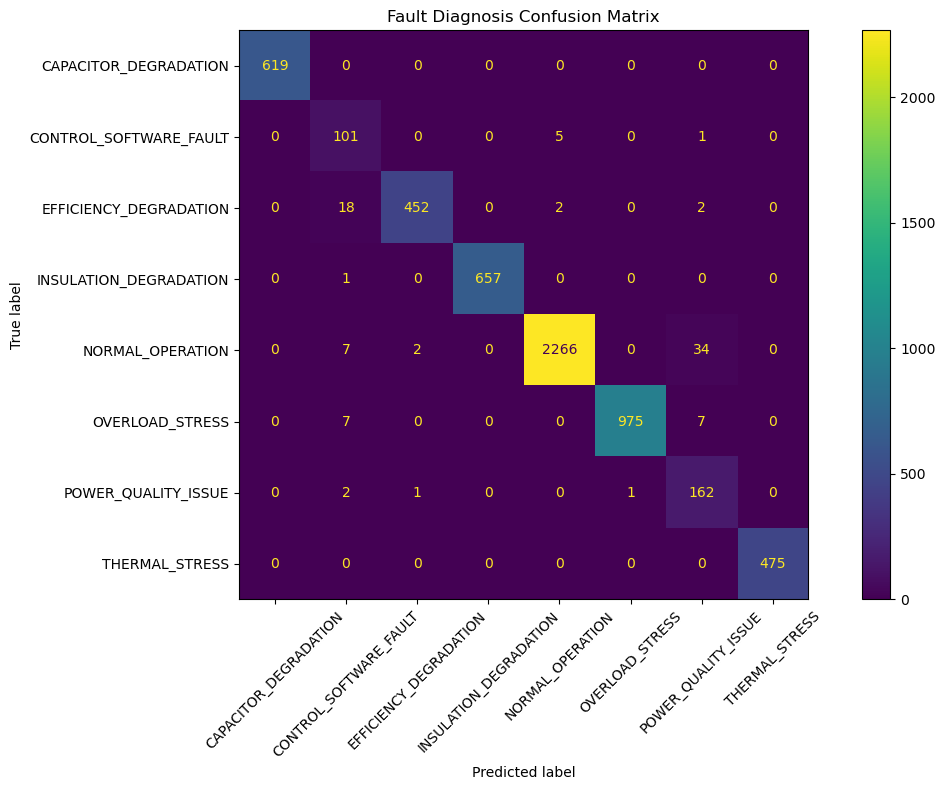

In [17]:
# Confusion matrix for fault diagnosis
labels = sorted(y_diagnosis.unique())
cm = confusion_matrix(y_diag_test, y_diag_pred, labels=labels)

fig, ax = plt.subplots(figsize=(12, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, xticks_rotation=45, values_format="d")
plt.title("Fault Diagnosis Confusion Matrix")
plt.tight_layout()
plt.show()

## 11. Model 2: 7-Day Failure Risk Classifier

This model predicts whether an inverter is likely to fail within the next 7 days. This is important because the self-healing system should not blindly execute actions. It must understand whether the current asset state is low-risk, medium-risk, or high-risk before allowing remote remediation.

Algorithm used here: `GradientBoostingClassifier`.

Output: failure probability between 0 and 1.

In [18]:
# Binary failure-risk model

failure_risk_model = Pipeline(
    steps=[
        ("preprocess", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=100,
                max_depth=10,
                min_samples_leaf=8,
                class_weight="balanced_subsample",
                random_state=RANDOM_STATE,
                n_jobs=-1,
            ),
        ),
    ]
)

failure_risk_model.fit(X_train, y_fail_train)

y_fail_pred = failure_risk_model.predict(X_test)
y_fail_prob = failure_risk_model.predict_proba(X_test)[:, 1]

fail_accuracy = accuracy_score(y_fail_test, y_fail_pred)

print("7-day failure risk accuracy:", round(fail_accuracy, 4))

# AUC only works if both classes are present in the test set.
if y_fail_test.nunique() == 2:
    fail_auc = roc_auc_score(y_fail_test, y_fail_prob)
    print("7-day failure risk ROC-AUC:", round(fail_auc, 4))
else:
    fail_auc = np.nan
    print("ROC-AUC could not be calculated because only one class is present in the test set.")

print("\nClassification report:")
print(classification_report(y_fail_test, y_fail_pred))

7-day failure risk accuracy: 0.9931
7-day failure risk ROC-AUC: 0.9989

Classification report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      5653
           1       0.80      0.97      0.88       144

    accuracy                           0.99      5797
   macro avg       0.90      0.98      0.94      5797
weighted avg       0.99      0.99      0.99      5797



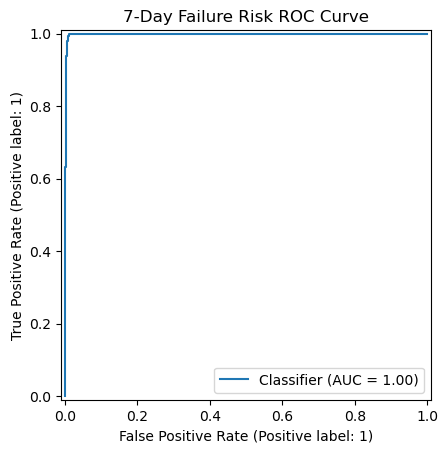

In [19]:
# ROC curve for failure-risk model
if y_fail_test.nunique() == 2:
    RocCurveDisplay.from_predictions(y_fail_test, y_fail_prob)
    plt.title("7-Day Failure Risk ROC Curve")
    plt.show()

## 12. Feature Importance

Feature importance helps explain which telemetry signals are most influential in the model. This is useful for technical review, manager feedback, debugging, model monitoring, and building trust with domain experts.

Top 20 diagnosis model features:


,feature,importance
17,insulation_resistance_mohm,0.141045
18,capacitor_degradation_indicator,0.107142
23,overload_events_today,0.098511
28,efficiency_decline_7d,0.076343
29,temp_stress_index,0.073416
14,internal_temperature_c,0.062901
16,current_harmonic_distortion_pct,0.057969
15,voltage_ripple,0.053193
3,age_months,0.052195
25,efficiency_30d_mean,0.045487


<Figure size 1000x600 with 0 Axes>

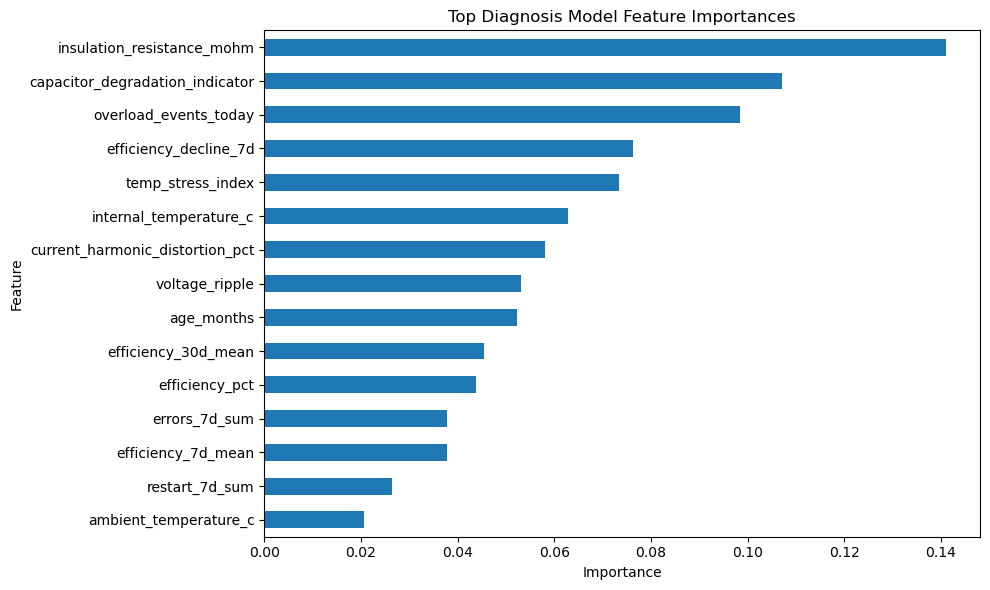

In [20]:
# Extract transformed feature names from the preprocessing pipeline

def get_feature_names(preprocessor):
    feature_names = []
    
    # Numeric feature names
    if "num" in preprocessor.named_transformers_:
        feature_names.extend(numeric_features)
    
    # Categorical one-hot names
    if "cat" in preprocessor.named_transformers_:
        cat_pipeline = preprocessor.named_transformers_["cat"]
        onehot = cat_pipeline.named_steps["onehot"]
        cat_names = onehot.get_feature_names_out(categorical_features).tolist()
        feature_names.extend(cat_names)
    
    return feature_names

# Feature importance for diagnosis model
feature_names = get_feature_names(diagnosis_model.named_steps["preprocess"])
rf_model = diagnosis_model.named_steps["model"]

importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

print("Top 20 diagnosis model features:")
display(importance_df.head(20))

plt.figure(figsize=(10, 6))
importance_df.head(15).sort_values("importance").plot(
    x="feature",
    y="importance",
    kind="barh",
    legend=False,
    figsize=(10, 6),
)
plt.title("Top Diagnosis Model Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 13. Rule-Based Remediation Policy

The PRD includes possible actions such as inverter reset, firmware rollback, parameter recalibration, isolation/bypass, and escalation to a human operator.

For this first prototype, actions are selected using an expert-policy function. This is safer than training a true RL model without action-outcome data.

The policy returns:

- Recommended action
- Reason
- Action risk level
- Whether human approval is required

In [21]:
# Rule-based remediation policy

LOW_RISK_ACTIONS = {
    "REMOTE_INVERTER_RESET",
    "PARAMETER_RECALIBRATION",
    "MONITOR_ONLY",
}

HIGH_RISK_ACTIONS = {
    "FIRMWARE_ROLLBACK",
    "ISOLATE_OR_BYPASS_INVERTER",
    "ESCALATE_TO_HUMAN_OPERATOR",
}


def recommend_remediation_action(row):
    diagnosis = row["predicted_diagnosis"]
    failure_prob = row["predicted_failure_7d_probability"]
    severity = row["remote_fix_severity_score"]
    
    # Hardware degradation should generally not be self-healed automatically.
    if diagnosis == "INSULATION_DEGRADATION":
        return pd.Series({
            "recommended_action": "ESCALATE_TO_HUMAN_OPERATOR",
            "action_reason": "Low insulation resistance indicates possible hardware/electrical safety risk.",
            "action_risk_level": "HIGH",
            "human_approval_required": True,
        })
    
    if diagnosis == "CAPACITOR_DEGRADATION":
        return pd.Series({
            "recommended_action": "ESCALATE_TO_HUMAN_OPERATOR",
            "action_reason": "Capacitor degradation is a hardware reliability issue that requires inspection.",
            "action_risk_level": "HIGH",
            "human_approval_required": True,
        })
    
    if diagnosis == "OVERLOAD_STRESS":
        return pd.Series({
            "recommended_action": "ISOLATE_OR_BYPASS_INVERTER",
            "action_reason": "Overload stress may damage equipment; isolation/bypass requires approval.",
            "action_risk_level": "HIGH",
            "human_approval_required": True,
        })
    
    if diagnosis == "THERMAL_STRESS":
        if failure_prob >= 0.50 or severity >= 70:
            return pd.Series({
                "recommended_action": "ESCALATE_TO_HUMAN_OPERATOR",
                "action_reason": "High thermal stress combined with elevated failure risk requires human review.",
                "action_risk_level": "HIGH",
                "human_approval_required": True,
            })
        return pd.Series({
            "recommended_action": "PARAMETER_RECALIBRATION",
            "action_reason": "Thermal stress is moderate; recalibration may reduce operating stress.",
            "action_risk_level": "MEDIUM",
            "human_approval_required": False,
        })
    
    if diagnosis == "POWER_QUALITY_ISSUE":
        return pd.Series({
            "recommended_action": "PARAMETER_RECALIBRATION",
            "action_reason": "Voltage ripple or harmonics suggest inverter parameter recalibration.",
            "action_risk_level": "MEDIUM",
            "human_approval_required": False,
        })
    
    if diagnosis == "CONTROL_SOFTWARE_FAULT":
        if failure_prob < 0.40:
            return pd.Series({
                "recommended_action": "REMOTE_INVERTER_RESET",
                "action_reason": "Repeated restarts/errors suggest a recoverable software-control issue.",
                "action_risk_level": "LOW",
                "human_approval_required": False,
            })
        return pd.Series({
            "recommended_action": "FIRMWARE_ROLLBACK",
            "action_reason": "Software-control fault with high failure risk may require firmware rollback approval.",
            "action_risk_level": "HIGH",
            "human_approval_required": True,
        })
    
    if diagnosis == "EFFICIENCY_DEGRADATION":
        return pd.Series({
            "recommended_action": "ESCALATE_TO_HUMAN_OPERATOR",
            "action_reason": "Efficiency degradation may indicate panel, inverter, or environmental issue requiring review.",
            "action_risk_level": "MEDIUM",
            "human_approval_required": True,
        })
    
    return pd.Series({
        "recommended_action": "MONITOR_ONLY",
        "action_reason": "No strong fault signature detected.",
        "action_risk_level": "LOW",
        "human_approval_required": False,
    })

print("Remediation policy function created successfully.")

Remediation policy function created successfully.


## 14. Safety Gate

The safety gate decides whether the recommended action can be executed automatically.

A recommended action is eligible for autonomous execution only if:

1. The action is low or medium operational risk
2. Human approval is not required
3. Predicted 7-day failure probability is below the safety threshold
4. The inverter has not already failed today
5. There are no critical hardware fault signatures

This is important because self-healing systems must prioritise safety over automation.

In [ ]:
# Safety gate configuration

SAFETY_FAILURE_PROB_THRESHOLD = 0.45
SAFETY_SEVERITY_THRESHOLD = 65
CRITICAL_DIAGNOSES = {
    "INSULATION_DEGRADATION",
    "CAPACITOR_DEGRADATION",
    "OVERLOAD_STRESS",
}


def safety_gate(row):
    reasons = []
    
    if row["recommended_action"] in HIGH_RISK_ACTIONS:
        reasons.append("Recommended action is high risk.")
    
    if row["human_approval_required"]:
        reasons.append("Human approval required by policy.")
    
    if row["predicted_failure_7d_probability"] >= SAFETY_FAILURE_PROB_THRESHOLD:
        reasons.append("Predicted 7-day failure probability exceeds safety threshold.")
    
    if row["remote_fix_severity_score"] >= SAFETY_SEVERITY_THRESHOLD:
        reasons.append("Remote-fix severity score exceeds safety threshold.")
    
    if row["predicted_diagnosis"] in CRITICAL_DIAGNOSES:
        reasons.append("Critical hardware-related diagnosis detected.")
    
    if row.get("failed_today", 0) == 1:
        reasons.append("Asset has already failed today.")
    
    eligible = len(reasons) == 0
    
    return pd.Series({
        "auto_execute_eligible": eligible,
        "safety_gate_status": "PASS" if eligible else "BLOCKED",
        "safety_gate_reasons": " | ".join(reasons) if reasons else "Safe for low-risk autonomous action.",
    })

print("Safety gate function created successfully.")

## 15. Generate Predictions and Action Plan

This section applies the diagnosis model, failure-risk model, remediation policy, and safety gate to the full dataset. In a production system, this section would run as a daily batch job or near-real-time inference process.

In [ ]:
# Generate model predictions for the full dataset

prediction_df = df.copy()
prediction_features = prediction_df[feature_cols].copy()

prediction_df["predicted_diagnosis"] = diagnosis_model.predict(prediction_features)
prediction_df["predicted_failure_7d_probability"] = failure_risk_model.predict_proba(prediction_features)[:, 1]

# Convert probability into a risk band for easy interpretation.
def failure_risk_band(prob):
    if prob < 0.20:
        return "LOW"
    if prob < 0.45:
        return "MEDIUM"
    if prob < 0.70:
        return "HIGH"
    return "CRITICAL"

prediction_df["predicted_failure_risk_band"] = prediction_df["predicted_failure_7d_probability"].apply(failure_risk_band)

# Apply remediation policy and safety gate
policy_outputs = prediction_df.apply(recommend_remediation_action, axis=1)
prediction_df = pd.concat([prediction_df, policy_outputs], axis=1)

safety_outputs = prediction_df.apply(safety_gate, axis=1)
prediction_df = pd.concat([prediction_df, safety_outputs], axis=1)

# Display key action-plan columns
action_plan_cols = [
    "date",
    "inverter_id",
    "manufacturer",
    "climate_zone",
    "predicted_diagnosis",
    "predicted_failure_7d_probability",
    "predicted_failure_risk_band",
    "remote_fix_severity_score",
    "remote_fix_severity_band",
    "recommended_action",
    "action_risk_level",
    "human_approval_required",
    "auto_execute_eligible",
    "safety_gate_status",
    "safety_gate_reasons",
]

print("Generated action-plan table:")
display(prediction_df[action_plan_cols].head(10))

In [ ]:
# Summary of recommended actions
summary_action = (
    prediction_df.groupby(["recommended_action", "safety_gate_status"])
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

summary_action["percent"] = (summary_action["count"] / len(prediction_df) * 100).round(2)
display(summary_action)

plt.figure(figsize=(10, 5))
prediction_df["recommended_action"].value_counts().plot(kind="bar")
plt.title("Recommended Remediation Actions")
plt.xlabel("Action")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# High-priority cases for manager/domain review
high_priority_cases = prediction_df[
    (prediction_df["predicted_failure_risk_band"].isin(["HIGH", "CRITICAL"]))
    | (prediction_df["remote_fix_severity_band"].isin(["HIGH", "CRITICAL"]))
    | (prediction_df["safety_gate_status"] == "BLOCKED")
].copy()

high_priority_cases = high_priority_cases.sort_values(
    ["predicted_failure_7d_probability", "remote_fix_severity_score"],
    ascending=False,
)

print("High-priority cases:", high_priority_cases.shape[0])
display(high_priority_cases[action_plan_cols].head(20))

## 16. Rollback Simulation

In production, every automated action should be monitored after execution. If the action worsens the system state, the system should automatically trigger a rollback.

Because this synthetic dataset does not contain real post-action outcomes, this notebook simulates rollback logic using a conservative rule.

Rollback is triggered if, after the action:

- Failure probability increases by more than 5 percentage points, or
- Severity score increases by more than 10 points, or
- A critical safety diagnosis is detected

This section demonstrates what the rollback/audit logic would look like in production.

In [ ]:
# Simulate post-action monitoring for auto-eligible rows.
# This does not claim real remediation success. It only demonstrates the production logic.

rollback_df = prediction_df[action_plan_cols + ["failed_today"]].copy()

def simulate_post_action(row):
    auto = row["auto_execute_eligible"]
    action = row["recommended_action"]
    current_prob = row["predicted_failure_7d_probability"]
    current_severity = row["remote_fix_severity_score"]
    diagnosis = row["predicted_diagnosis"]
    
    if not auto:
        return pd.Series({
            "action_executed": False,
            "post_action_failure_probability": current_prob,
            "post_action_severity_score": current_severity,
            "rollback_triggered": False,
            "rollback_reason": "Action not executed automatically.",
        })
    
    # Conservative simulated effect by action type
    if action == "REMOTE_INVERTER_RESET":
        prob_change = -0.05
        severity_change = -6
    elif action == "PARAMETER_RECALIBRATION":
        prob_change = -0.03
        severity_change = -4
    elif action == "MONITOR_ONLY":
        prob_change = 0.00
        severity_change = 0
    else:
        prob_change = 0.04
        severity_change = 5
    
    # Add small noise so the simulation does not look artificially perfect.
    prob_noise = np.random.normal(0, 0.015)
    severity_noise = np.random.normal(0, 2.0)
    
    post_prob = float(np.clip(current_prob + prob_change + prob_noise, 0, 1))
    post_severity = float(np.clip(current_severity + severity_change + severity_noise, 0, 100))
    
    rollback = False
    reasons = []
    
    if post_prob > current_prob + 0.05:
        rollback = True
        reasons.append("Failure probability worsened after action.")
    
    if post_severity > current_severity + 10:
        rollback = True
        reasons.append("Severity score worsened after action.")
    
    if diagnosis in CRITICAL_DIAGNOSES:
        rollback = True
        reasons.append("Critical hardware diagnosis detected after action.")
    
    return pd.Series({
        "action_executed": True,
        "post_action_failure_probability": post_prob,
        "post_action_severity_score": post_severity,
        "rollback_triggered": rollback,
        "rollback_reason": " | ".join(reasons) if reasons else "No rollback required.",
    })

rollback_outputs = rollback_df.apply(simulate_post_action, axis=1)
rollback_df = pd.concat([rollback_df, rollback_outputs], axis=1)

print("Rollback simulation summary:")
display(rollback_df[["action_executed", "rollback_triggered"]].value_counts().to_frame("count"))

display(rollback_df.head(10))

## 17. Audit Trail Generation

A self-healing system must create a complete audit trail. Each record should show asset ID, timestamp, predicted diagnosis, risk score, recommended action, safety-gate decision, execution status, rollback status, and the reason for the decision.

In [ ]:
# Build final audit trail

audit_columns = [
    "date",
    "inverter_id",
    "manufacturer",
    "climate_zone",
    "predicted_diagnosis",
    "predicted_failure_7d_probability",
    "predicted_failure_risk_band",
    "remote_fix_severity_score",
    "remote_fix_severity_band",
    "recommended_action",
    "action_reason",
    "action_risk_level",
    "human_approval_required",
    "auto_execute_eligible",
    "safety_gate_status",
    "safety_gate_reasons",
]

final_audit_df = prediction_df[audit_columns].merge(
    rollback_df[[
        "date",
        "inverter_id",
        "action_executed",
        "post_action_failure_probability",
        "post_action_severity_score",
        "rollback_triggered",
        "rollback_reason",
    ]],
    on=["date", "inverter_id"],
    how="left",
)

# Round numeric columns for cleaner export
round_cols = [
    "predicted_failure_7d_probability",
    "remote_fix_severity_score",
    "post_action_failure_probability",
    "post_action_severity_score",
]

for col in round_cols:
    final_audit_df[col] = final_audit_df[col].round(4)

print("Final audit trail shape:", final_audit_df.shape)
display(final_audit_df.head(10))

## 18. Business and Technical KPI Summary

This section creates simple KPI outputs that can be used in documentation or email updates.

In [ ]:
# KPI summary

total_records = len(final_audit_df)
auto_eligible_count = int(final_audit_df["auto_execute_eligible"].sum())
blocked_count = int((final_audit_df["safety_gate_status"] == "BLOCKED").sum())
human_approval_count = int(final_audit_df["human_approval_required"].sum())
executed_count = int(final_audit_df["action_executed"].sum())
rollback_count = int(final_audit_df["rollback_triggered"].sum())

kpi_summary = pd.DataFrame({
    "metric": [
        "Total observations processed",
        "Auto-execute eligible actions",
        "Safety-gate blocked actions",
        "Human approval required",
        "Simulated actions executed",
        "Simulated rollbacks triggered",
        "Fault diagnosis test accuracy",
        "7-day failure risk test accuracy",
        "7-day failure risk ROC-AUC",
    ],
    "value": [
        total_records,
        auto_eligible_count,
        blocked_count,
        human_approval_count,
        executed_count,
        rollback_count,
        round(diag_accuracy, 4),
        round(fail_accuracy, 4),
        round(fail_auc, 4) if not np.isnan(fail_auc) else "N/A",
    ],
})

kpi_summary["percent_of_records"] = ""
for idx, metric in enumerate(kpi_summary["metric"]):
    if metric in [
        "Auto-execute eligible actions",
        "Safety-gate blocked actions",
        "Human approval required",
        "Simulated actions executed",
        "Simulated rollbacks triggered",
    ]:
        value = kpi_summary.loc[idx, "value"]
        kpi_summary.loc[idx, "percent_of_records"] = f"{(value / total_records * 100):.2f}%"

print("KPI Summary:")
display(kpi_summary)

## 19. Export Model Artefacts and Output Files

The notebook exports:

1. Fault diagnosis model pipeline
2. Failure-risk model pipeline
3. Full action-plan audit trail
4. KPI summary
5. Feature importance table

These files can be shared, reviewed, or connected to a future dashboard/API prototype.

In [ ]:
# Export model pipelines

diagnosis_model_path = model_dir / "automated_rfsh_fault_diagnosis_model.joblib"
failure_model_path = model_dir / "automated_rfsh_failure_risk_model.joblib"

joblib.dump(diagnosis_model, diagnosis_model_path)
joblib.dump(failure_risk_model, failure_model_path)

# Export outputs
full_audit_path = output_dir / "automated_rfsh_action_audit_trail.csv"
kpi_summary_path = output_dir / "automated_rfsh_kpi_summary.csv"
feature_importance_path = output_dir / "automated_rfsh_feature_importance.csv"
action_summary_path = output_dir / "automated_rfsh_action_summary.csv"

final_audit_df.to_csv(full_audit_path, index=False)
kpi_summary.to_csv(kpi_summary_path, index=False)
importance_df.to_csv(feature_importance_path, index=False)
summary_action.to_csv(action_summary_path, index=False)

print("Export complete.")
print("Diagnosis model:", diagnosis_model_path)
print("Failure risk model:", failure_model_path)
print("Audit trail:", full_audit_path)
print("KPI summary:", kpi_summary_path)
print("Feature importance:", feature_importance_path)
print("Action summary:", action_summary_path)

## 20. Example Inference Function

This section shows how the trained prototype could be converted into a reusable inference function. In production, this function would sit behind an API endpoint or scheduled batch process.

In [ ]:
def run_rfsh_inference(new_data):
    """
    Run Automated Remote Fixing & Self-Healing inference on new inverter telemetry.
    
    Parameters
    ----------
    new_data : pandas.DataFrame
        New inverter telemetry with the same schema as the training features.
    
    Returns
    -------
    pandas.DataFrame
        Action-plan output with diagnosis, failure risk, recommended action, and safety decision.
    """
    data = new_data.copy()
    
    # Ensure time features exist if a date column is present.
    if "date" in data.columns:
        data["date"] = pd.to_datetime(data["date"], errors="coerce")
        data["month"] = data["date"].dt.month
        data["quarter"] = data["date"].dt.quarter
        data["day_of_year"] = data["date"].dt.dayofyear
        data["season"] = data["month"].apply(season_from_month)
    
    # Use only model features.
    model_input = data[feature_cols].copy()
    
    output = data.copy()
    output["predicted_diagnosis"] = diagnosis_model.predict(model_input)
    output["predicted_failure_7d_probability"] = failure_risk_model.predict_proba(model_input)[:, 1]
    output["predicted_failure_risk_band"] = output["predicted_failure_7d_probability"].apply(failure_risk_band)
    
    # If severity score does not exist, approximate it using a neutral value.
    # In production this should be converted into a shared feature-engineering pipeline.
    if "remote_fix_severity_score" not in output.columns:
        output["remote_fix_severity_score"] = 0
        output["remote_fix_severity_band"] = "UNKNOWN"
    
    policy = output.apply(recommend_remediation_action, axis=1)
    output = pd.concat([output, policy], axis=1)
    
    safety = output.apply(safety_gate, axis=1)
    output = pd.concat([output, safety], axis=1)
    
    return output

# Example: run inference on the first 5 rows
example_output = run_rfsh_inference(df.head(5))
display(example_output[action_plan_cols])

## 21. Prototype Interpretation

This prototype demonstrates how Automated Remote Fixing & Self-Healing can be implemented safely using the currently available dataset.

### What the model does well

- Diagnoses likely fault categories from inverter telemetry
- Estimates short-term failure risk
- Separates low-risk remote actions from high-risk human-review cases
- Creates an audit trail for every recommended action
- Demonstrates rollback logic for autonomous actions

### What should not be claimed yet

This prototype should not claim that it has learned a true reinforcement learning remediation policy, because the dataset does not contain historical action-outcome data.

### What is required for a future RL version

To train a proper RL or offline-RL remediation agent, the project would need:

1. Historical remediation action logs
2. Success/failure outcome after each action
3. Post-action telemetry windows
4. Digital twin simulation environment
5. Safety constraints and reward function validation
6. Human-approved action boundaries

### Recommended next step

The recommended next step is to share this prototype for review and confirm whether the remediation policy rules should be adjusted based on domain-expert feedback.